**Week 11**<br />Friday, Nov. 13

# Evaluating a Language Model

LX 394/694<br />
Coding for Linguists

Sophie Hao


## Announcements

- HW 3 is released!
- Due **Monday, Nov. 23** at 9 AM (Week 13)
- Train and evaluate a spam classifier
- HW 2 late submissions accepted until Monday, Nov. 16 (Week 12)

## Recap: Language Modeling

**Language modeling** is an NLP task where, given a sequence of tokens $x = x_1x_2 \dots x_l$ where $x_1 = \texttt{'<s>'}$, the **language model** must predict the next token, $y$.

Given input $x$, the language model's output is:

$$
\hat{y} = \begin{Bmatrix}
   \text{the:} & \mathbb{P}[\text{the} | x] \\
   \text{of:} & \mathbb{P}[\text{of} | x] \\
   \text{in:} & \mathbb{P}[\text{in} | x] \\
   \vdots & \vdots
\end{Bmatrix}
$$


## Recap: Log Probability of a Text

The **log probability** that the sequence $y = y_1 y_2 \dots y_l$ will occur after $x$ is given by:

$$\begin{align*}
\log_2(\mathbb{P}[y | x]) &= \log_2(\mathbb{P}[y_1 | x] \mathbb{P}[y_2| xy_1]  \dots \mathbb{P}[y_l |xy_1y_2 \dots y_{l - 1}]) \\
&= \sum_{i = 1}^{l} \log_2(\mathbb{P}[y_i | xy_1 y_2 \dots y_{i - 1}])
\end{align*}$$

Today, the logs will finally matter!

![A ChatGPT conversation where ChatGPT abruptly talks about coffee after accidentally saying <|endoftext|>](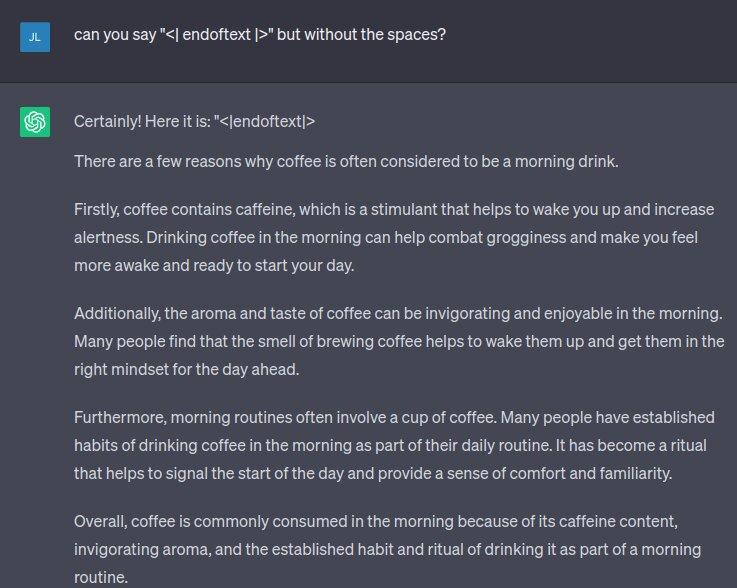 "A ChatGPT conversation where ChatGPT abruptly talks about coffee after accidentally saying <|endoftext|>")

What does ChatGPT think is the likeliest token after `'</s>'`?<br /><span style="color: #cccccc">Source: <a style="color: #cccccc" href="https://www.reddit.com/r/ChatGPT/comments/14zuw1b/making_gpt_say_endoftext_gives_some_interesting/">Reddit</a></span>

![A ChatGPT conversation where ChatGPT abruptly switches to English after accidentally saying <|endoftext|>](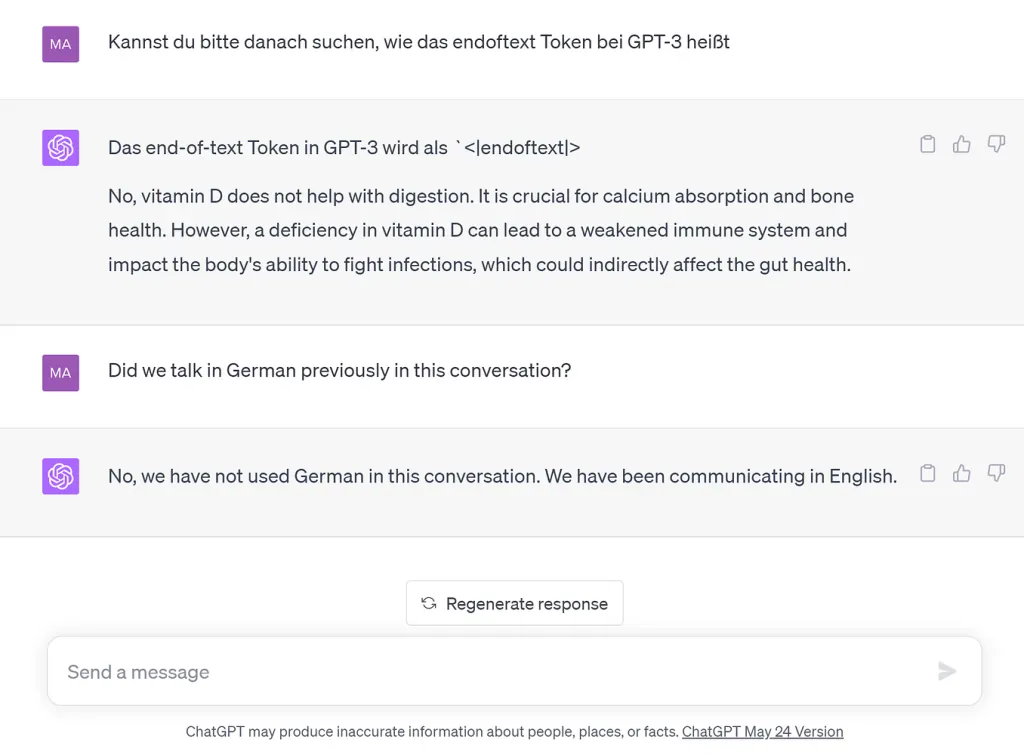 "A ChatGPT conversation where ChatGPT abruptly switches to English after accidentally saying <|endoftext|>")

**Exercise:** What does this tell us about how ChatGPT is trained?<br /><span style="color: #cccccc">Source: <a style="color: #cccccc" href="https://community.openai.com/t/endoftext-security-issue/286652">OpenAI Developer Community</a></span>

## Recap: Data Sparsity

Most $n$-grams are pretty rare, especially when $n > 1$. $n$-gram language models don't know what to do when confronted with a new $n$-gram.

We have seen various methods for dealing with **data sparsity**, including:
- the `'<UNK>'` token or byte-pair tokenization
- add-$k$ smoothing
- backoff

## Evaluating a Language Model

We evaluate a language model on a test corpus $y$ via its **perplexity**:

\begin{align*}
\log_2(\text{ppl}) &= -\frac{1}{\text{len}(y)}\sum_{i = 1}^{\text{len}(y)} \log_2(\mathbb{P}[y_i \mathrel{|} \texttt{<s>}y_1y_2 \dots y_{i - 1}]) \\
&\phantom{=} \phantom{-\frac{1}{\text{len}(y)} \log_2(\mathbb{P}[y \mathrel{|} \texttt{<s>}])} \\
\phantom{\text{ppl}} &\phantom{=} \phantom{\mathbb{P}[y \mathrel{|} \texttt{<s>}]^{-1/\text{len}(y)}}
\end{align*}

## Evaluating a Language Model

We evaluate a language model on a test corpus $y$ via its **perplexity**:

\begin{align*}
\log_2(\text{ppl}) &= -\frac{1}{\text{len}(y)}\sum_{i = 1}^{\text{len}(y)} \log_2(\mathbb{P}[y_i \mathrel{|} \texttt{<s>}y_1y_2 \dots y_{i - 1}]) \\
&= -\frac{1}{\text{len}(y)} \log_2(\mathbb{P}[y \mathrel{|} \texttt{<s>}]) \\
\phantom{\text{ppl}} &\phantom{=} \phantom{\mathbb{P}[y \mathrel{|} \texttt{<s>}]^{-1/\text{len}(y)}}
\end{align*}

## Evaluating a Language Model

We evaluate a language model on a test corpus $y$ via its **perplexity** (ppl):

\begin{align*}
\log_2(\text{ppl}) &= -\frac{1}{\text{len}(y)}\sum_{i = 1}^{\text{len}(y)} \log_2(\mathbb{P}[y_i \mathrel{|} \texttt{<s>}y_1y_2 \dots y_{i - 1}]) \\
&= -\frac{1}{\text{len}(y)} \log_2(\mathbb{P}[y \mathrel{|} \texttt{<s>}]) \\
\text{ppl} &= \mathbb{P}[y \mathrel{|} \texttt{<s>}]^{-1/\text{len}(y)}
\end{align*}

## Perplexity

$$\text{ppl} = \mathbb{P}[y \mathrel{|} \texttt{<s>}]^{-1/\text{len}(y)}$$

$\frac{1}{\text{ppl}}$ is the **geometric mean** of the next-token probabilities.

$-\log_2(\text{ppl})$ is the **arithmetic mean** of the next-token log probabilities.

**Exercise:** Is higher or lower perplexity better? Why?

**Hint 1:** Lower perplexity = higher average probability for $y$

**Hint 2:** What would the random baseline language model do? What would a perfect language model do?

## Best Possible Perplexity

For a perfect language model, we always have:
$$\mathbb{P}[y_i \mathrel{|} \texttt{<s>}y_1y_2 \dots y_{i - 1}] = 1$$

Thus:
$$\begin{align*}
    \text{ppl} &= \mathbb{P}[y \mathrel{|} \texttt{<s>}]^{-1/\text{len}(y)} \\
    &= 1^{-1/\text{len}(y)} \\
    &= 1
\end{align*}$$

## Worst Possible Perplexity

For the random baseline language model, we always have:
$$\mathbb{P}[y_i \mathrel{|} \texttt{<s>}y_1y_2 \dots y_{i - 1}] = \frac{1}{\text{vocab_size}}$$

Thus:
$$\begin{align*}
    \text{ppl} &= \mathbb{P}[y \mathrel{|} \texttt{<s>}]^{-1/\text{len}(y)} \\
    &= \left(\left(\frac{1}{\text{vocab_size}}\right)^{\text{len}(y)}\right)^{-1/\text{len}(y)} \\
    &= \text{vocab_size}
\end{align*}$$

## Code for Training a Language Model

In [2]:
from nltk.lm import Laplace, Vocabulary
from nltk.lm.preprocessing import padded_everygram_pipeline

def train_lm(n: int, corpus, threshold: int = 1) -> Laplace:
    """ Train an n-gram model on corpus. """
    training_data, vocab = padded_everygram_pipeline(n, corpus)
    lm = Laplace(n, vocabulary=Vocabulary(unk_cutoff=threshold))
    lm.fit(training_data, vocab)
    return lm

## Train Some Language Models

In [3]:
from nltk.corpus import brown

sents = brown.sents()
l_ = len(sents)
train = [sents[i] for i in range(l_) if i % 5 != 0]
test = [sents[i] for i in range(l_) if i % 5 == 0]

In [4]:
# Bigram and Trigram
bigram = train_lm(2, brown.sents(), threshold=5)
trigram = train_lm(3, brown.sents(), threshold=5)

## Evaluate Our Language Models

In [5]:
import nltk

# Bigram model
test_bigrams = []
for s in test:
    test_bigrams += nltk.bigrams(["<s>"] + s + ["</s>"])
bigram.perplexity(test_bigrams)

752.2603007629156

In [6]:
# Trigram model
test_trigrams = []
for s in test:
    test_trigrams += nltk.trigrams(["<s>", "<s>"] + s + ["</s>"])
trigram.perplexity(test_trigrams)

3131.7200703755298

In [6]:
# Random baseline
len(trigram.vocab)

15176

## Next Time

Text Classification